In [2]:
#CREAR MODELOS DE MACHINE LEARNING

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import sklearn
from sklearn import datasets
from sklearn import linear_model
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

plt.rcParams["font.size"] = 15 #Definir el tamaño de las graficas

In [14]:
iris= datasets.load_iris()

data= pd.DataFrame(data= iris.data, columns= iris.feature_names) #Crear el DataFrame con los feature names
target= pd.DataFrame(data= iris.target, columns= ["species"]) #Crear el DataFrame con los targets (las especies de la flor)
data= pd.concat([data, target], axis= 1) #Unir ambos df y agregar una nueva columna
data= data.sample(frac= 1, random_state= 1234) # Mezclar en orden aleatorio

#Separar datos en training y testing

Ntrain= int(data.shape[0]*0.8) # Fracción de entrenamiento 0.8
train= data.iloc[:Ntrain,:] #Datos de entrenamiento
test= data.iloc[Ntrain:,:] #Datos de prueba

<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

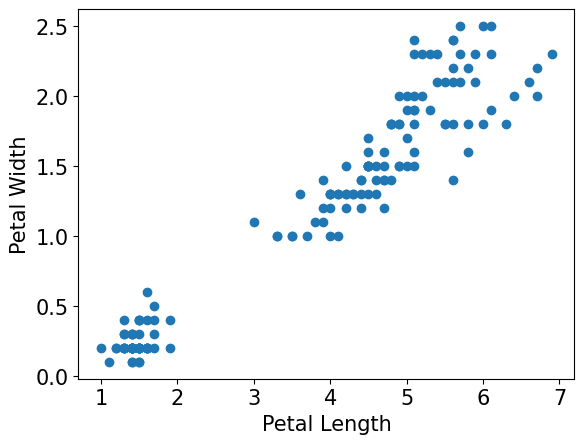

In [25]:
#REGRESION LINEAL

plength = data["petal length (cm)"]
pwidth = data["petal width (cm)"]

plt.scatter(plength, pwidth)
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.tight_layout

In [24]:
model_1 = linear_model.LinearRegression()  #Inicializar el modelo
model_1.fit(pd.DataFrame(train.iloc[:, 2]), train.iloc[:,3]) #Ajustar el modelo
print(f"Coeficientes: {model_1.coef_.round(3)}") #Imprimir los coeficientes
print(f"Bias: {model_1.intercept_.round(3)}") #Imprimir el sesgo o bias

Coeficientes: [0.415]
Bias: -0.358


<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

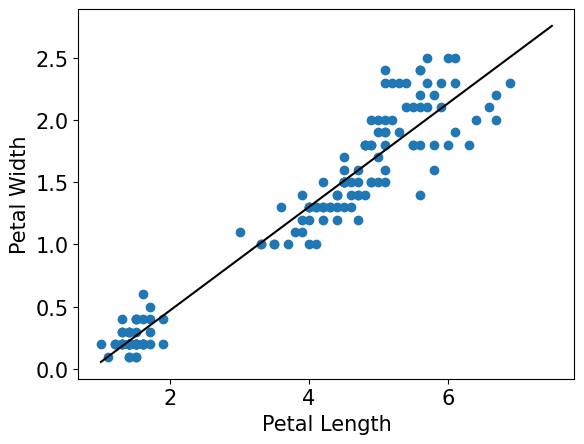

In [28]:
#Graficar

plength = data["petal length (cm)"]
pwidth = data["petal width (cm)"]

xvals = np.arange(plength.min(), plength.max()+1, 0.5) # Definimos un arreglo desde el valor mímimo del petal length hasta el máximo del petal lenght + 1, en pasos de 0.5
yvals= 0.415*xvals -0.358 #Ecuación de la regresión lineal

plt.scatter(plength, pwidth)
plt.plot(xvals, yvals, "k")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.tight_layout

In [32]:
ypredict= model_1.predict(pd.DataFrame(test.iloc[:,2])) #Prediccion usando los datos de prueba
MSE = mean_squared_error(pd.DataFrame(test.iloc[:, 3]), ypredict) #Calcular el Error Cuadrático Medio (MSE) 
print(f"MSE: {MSE.round(3)}")

R2= r2_score(pd.DataFrame(test.iloc[:, 3]), ypredict) #Calcular el R2
print(f"R2: {R2.round(3)}")


MSE: 0.043
R2: 0.937
